# Netflix Titles: Python Practice Question Set
**Libraries:** NumPy, Pandas, Matplotlib, Seaborn  
**Dataset:** `netflix_titles.csv` (6,234 rows, 12 columns)  
**Levels:** Beginner → Basic → Intermediate → Advanced → Expert → Capstone

**How to use:** Read each question and write your answer in the code cell below it.

**Columns:** `show_id, type, title, director, cast, country, date_added, release_year, rating, duration, listed_in, description`

## Setup (run this first)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("netflix_titles.csv")
df

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,81145628,Movie,Norm of the North: King Sized Adventure,"Richard Finn, Tim Maltby","Alan Marriott, Andrew Toth, Brian Dobson, Cole...","United States, India, South Korea, China","September 9, 2019",2019,TV-PG,90 min,"Children & Family Movies, Comedies",Before planning an awesome wedding for his gra...
1,80117401,Movie,Jandino: Whatever it Takes,NaN,Jandino Asporaat,United Kingdom,"September 9, 2016",2016,TV-MA,94 min,Stand-Up Comedy,Jandino Asporaat riffs on the challenges of ra...
2,70234439,TV Show,Transformers Prime,NaN,"Peter Cullen, Sumalee Montano, Frank Welker, J...",United States,"September 8, 2018",2013,TV-Y7-FV,1 Season,Kids' TV,"With the help of three human allies, the Autob..."
3,80058654,TV Show,Transformers: Robots in Disguise,NaN,"Will Friedle, Darren Criss, Constance Zimmer, ...",United States,"September 8, 2018",2016,TV-Y7,1 Season,Kids' TV,When a prison ship crash unleashes hundreds of...
4,80125979,Movie,#realityhigh,Fernando Lebrija,"Nesta Cooper, Kate Walsh, John Michael Higgins...",United States,"September 8, 2017",2017,TV-14,99 min,Comedies,When nerdy high schooler Dani finally attracts...
...,...,...,...,...,...,...,...,...,...,...,...,...
6229,80000063,TV Show,Red vs. Blue,NaN,"Burnie Burns, Jason Saldaña, Gustavo Sorola, G...",United States,NaN,2015,NR,13 Seasons,"TV Action & Adventure, TV Comedies, TV Sci-Fi ...","This parody of first-person shooter games, mil..."
6230,70286564,TV Show,Maron,NaN,"Marc Maron, Judd Hirsch, Josh Brener, Nora Zeh...",United States,NaN,2016,TV-MA,4 Seasons,TV Comedies,"Marc Maron stars as Marc Maron, who interviews..."
6231,80116008,Movie,Little Baby Bum: Nursery Rhyme Friends,NaN,NaN,NaN,NaN,2016,NaN,60 min,Movies,Nursery rhymes and original music for children...
6232,70281022,TV Show,A Young Doctor's Notebook and Other Stories,NaN,"Daniel Radcliffe, Jon Hamm, Adam Godley, Chris...",United Kingdom,NaN,2013,TV-MA,2 Seasons,"British TV Shows, TV Comedies, TV Dramas","Set during the Russian Revolution, this comic ..."


---
# Level 1: Beginner (loading and inspecting)
*Skills: head, info, describe, value_counts, isnull, simple filters*

### Q1. Shape and data types
How many rows and columns are in the dataset? What is the data type of each column?

In [8]:
#  To count the number of rows in the dataset 
len(df)


6234

In [15]:
# To count the number of columns in the dataset 
df.nunique().count()

np.int64(12)

In [17]:
# The datatype of each of the columns is shown below
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6234 entries, 0 to 6233
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       6234 non-null   int64
 1   type          6234 non-null   str  
 2   title         6234 non-null   str  
 3   director      4265 non-null   str  
 4   cast          5664 non-null   str  
 5   country       5758 non-null   str  
 6   date_added    6223 non-null   str  
 7   release_year  6234 non-null   int64
 8   rating        6224 non-null   str  
 9   duration      6234 non-null   str  
 10  listed_in     6234 non-null   str  
 11  description   6234 non-null   str  
dtypes: int64(2), str(10)
memory usage: 584.6 KB


### Q2. Movies vs TV Shows
How many titles are Movies and how many are TV Shows? Show the result as a bar chart with a title and axis labels.

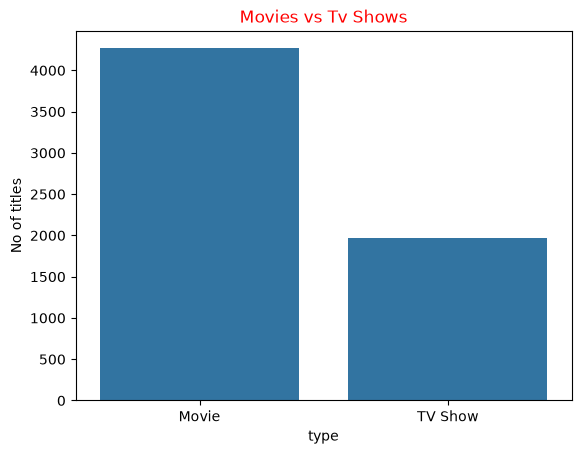

In [34]:
movies_vs_shows=df.groupby('type')['title'].count()
sns.barplot(x=movies_vs_shows.index,y=movies_vs_shows.values)
plt.title("Movies vs Tv Shows",color='red')
plt.ylabel("No of titles")
plt.show()


### Q3. Missing values
Which columns have missing values? Show the count **and** the percentage of missing values per column, sorted from highest to lowest.

In [37]:
# To show the count of the missing values per columns sorted from highest to lowest 
df.isnull().sum().sort_values(ascending=False)



director        1969
cast             570
country          476
date_added        11
rating            10
show_id            0
type               0
title              0
release_year       0
duration           0
listed_in          0
description        0
dtype: int64

In [41]:
# To show the percentage of the missing values per columns sorted from highest to lowest
percentages= 100*df.isnull().sum()/(df.isnull().sum()).sum()
percentages.sort_values(ascending=False)

director        64.855072
cast            18.774704
country         15.678524
date_added       0.362319
rating           0.329381
show_id          0.000000
type             0.000000
title            0.000000
release_year     0.000000
duration         0.000000
listed_in        0.000000
description      0.000000
dtype: float64

### Q4. Release year range
What are the earliest and latest `release_year` in the catalog? Which title is the oldest?

In [27]:
a=df['release_year'].sort_values()
print("The earliest release_year is",a.head(1).unique()[0])
print("The latest release year is",a.tail(1).unique()[0])



The earliest release_year is 1925
The latest release year is 2020


In [28]:
# Oldest Title 
df[df['release_year']==a.head(1).unique()[0]]

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,desc_length
4292,81030762,TV Show,Pioneers: First Women Filmmakers*,NaN,NaN,NaN,"December 30, 2018",1925,TV-PG,1 Season,TV Shows,This collection restores films from women who ...,24


### Q5. Unique ratings
List all unique values in the `rating` column with the count of each.

In [89]:
a=df['rating']

print(f"The unique values of the rating are {a.unique()} and the total rating is {a.nunique()} ")

The unique values of the rating are <StringArray>
[   'TV-PG',    'TV-MA', 'TV-Y7-FV',    'TV-Y7',    'TV-14',        'R',
     'TV-Y',       'NR',    'PG-13',     'TV-G',       'PG',        'G',
        nan,       'UR',    'NC-17']
Length: 15, dtype: str and the total rating is 14 


### Q6. Filtering
Show all titles released in 2019 that are rated `TV-MA`. How many are there?

In [104]:
a=df.loc[
    (df['release_year'] == 2019) &
    (df['rating'] == 'TV-MA'),
    'title'
]

print(f"All titles release in 2019 that are rated TV-MA are {a.tolist} and the total titlte is {a.count()}")

All titles release in 2019 that are rated TV-MA are <bound method IndexOpsMixin.tolist of 35                        Article 15
39                           The Spy
62             Mo Gilligan: Momentum
99                     Bard of Blood
102        In the Shadow of the Moon
                    ...             
6164                      MINDHUNTER
6167                    Sacred Games
6188    Roman Empire: Reign of Blood
6198                   The Protector
6206                       Samantha!
Name: title, Length: 412, dtype: str> and the total titlte is 412


### Q7. Latest releases
Show the 10 most recent titles by `release_year`, displaying only `title`, `type` and `release_year`.

In [120]:
df.sort_values(by='release_year',ascending=False)[['title','type','release_year']].head(10)

,title,type,release_year
3467,Medical Police,TV Show,2020
3249,All the Freckles in the World,Movie,2020
3220,Dracula,TV Show,2020
3427,Leslie Jones: Time Machine,Movie,2020
3436,The Healing Powers of Dude,TV Show,2020
3195,"Live Twice, Love Once",Movie,2020
3189,Cheer,TV Show,2020
3464,AJ and the Queen,TV Show,2020
3180,Bulletproof 2,Movie,2020
3466,Jamtara - Sabka Number Ayega,TV Show,2020


### Q8. Country filter
How many titles contain "United States" anywhere in the `country` column?

In [202]:
df.loc[(df['country']=='United States'),'title'].count()


np.int64(41)

---
# Level 2: Basic Analysis (groupby, sorting, simple charts)
*Skills: groupby, sort_values, crosstab, countplot, fillna, drop_duplicates*

### Q9. Rating distribution
Plot the top 10 ratings by count using `sns.countplot`. Which rating dominates, and what does it say about Netflix's target audience? (Write your answer in a comment.)

/var/folders/pz/xmfgr8wn2mq8f5k40q6wznj80000gn/T/ipykernel_72568/4253018135.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df,x='rating',order=top10,palette='summer')


<Axes: xlabel='rating', ylabel='count'>

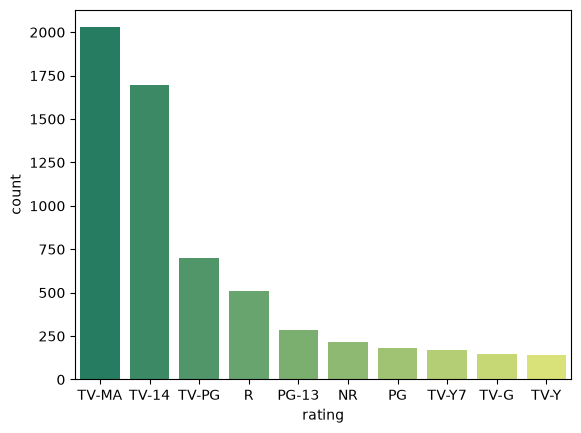

In [144]:
top10=df.groupby('rating')['rating'].count().sort_values(ascending=False).head(10).index
sns.countplot(data=df,x='rating',order=top10,palette='summer')
plt.title()

### Q10. Top countries (first listed)
Find the top 10 countries by number of titles, counting only the **first** country listed for each title. Plot as a horizontal bar chart.

/var/folders/pz/xmfgr8wn2mq8f5k40q6wznj80000gn/T/ipykernel_72568/3873525305.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=a.index,y=a.values,palette='summer')


<Axes: xlabel='country'>

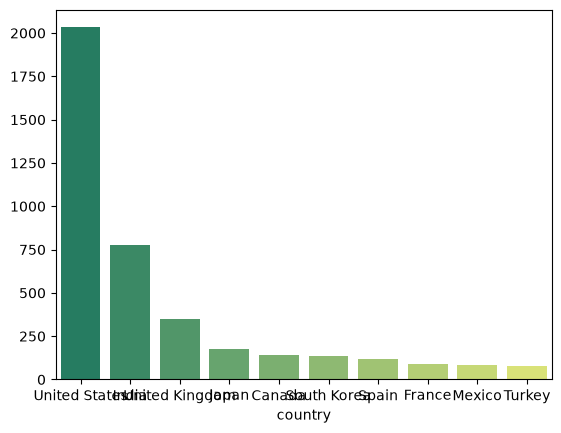

In [155]:
a=df.groupby('country')['title'].count().sort_values(ascending=False).head(10)
plt.figsize=(21,7)
plt.tight_layout()
sns.barplot(x=a.index,y=a.values,palette='summer')

### Q11. Titles per release year
How many titles were released in each year from 2010 to 2020? Draw a line chart with markers.

Text(0.5, 1.0, 'release_year vs no_of_titles')

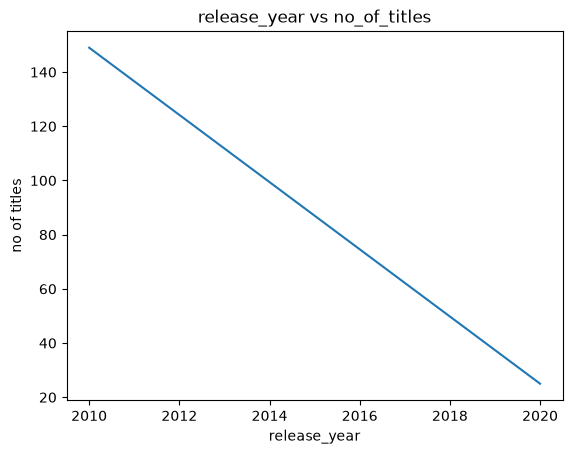

In [169]:
a=df[df['release_year'].isin([2010,2020])]
a=a.groupby('release_year')['title'].count()

sns.lineplot(x=a.index,y=a.values)
plt.ylabel("no of titles")
plt.title('release_year vs no_of_titles')


### Q12. Type vs rating
Create a crosstab of `type` vs `rating`. Show it as a stacked bar chart.

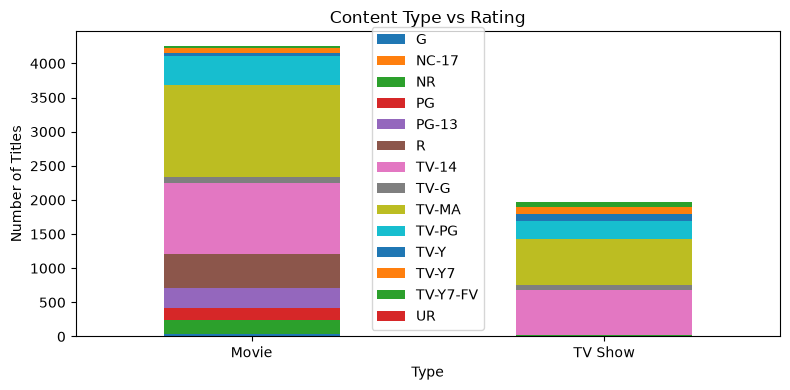

In [182]:

rating_table = pd.crosstab(df['type'], df['rating'])
rating_table.plot(kind='bar', stacked=True, figsize=(8, 4))
plt.title('Content Type vs Rating')
plt.xlabel('Type')
plt.ylabel('Number of Titles')
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

### Q13. Handle missing values
Create a cleaned copy `df_clean`:
- Fill missing `director`, `cast` and `country` with `"Unknown"`
- Drop rows where `rating` or `date_added` is missing

Report how many rows remain. In a comment, explain why you filled some columns but dropped rows for others.

In [191]:
df[['director','cast','country']]=df[['director','cast','country']].fillna('Unknown')
df[['rating','date_added']]=df[['rating','date_added']].dropna(inplace=True)
df[['rating','date_added']].isnull().sum()

# there are 174 rows for rating and date_added remains. 

# We use `fillna()` to replace missing values in important columns,
# such as filling missing ratings with `"Unknown"`,
# so we can preserve useful data for analysis. We use `drop()
# ` to remove unnecessary rows or columns that do not contribute useful information to our analysis. 
# The decision depends on the importance of the data: 
# fill missing values when the information is useful, and drop data only when removing it makes sense for the analysis.



rating        174
date_added    174
dtype: int64

### Q14. Percentage split
What percentage of the catalog is Movies and what percentage is TV Shows? Show it as a pie chart with percentage labels.

Text(0.5, 1.0, 'Percentage Distributions of Movies and TV shows')

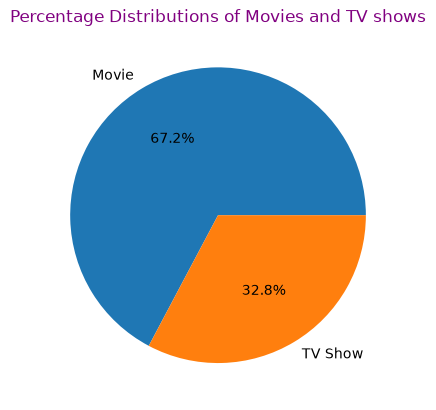

In [213]:
a = df[df['type'].isin(['Movie', 'TV Show'])]['type'].value_counts()
plt.pie(a.values,labels=a.index, autopct='%1.1f%%')
plt.title("Percentage Distributions of Movies and TV shows", color='Purple')

### Q15. Duplicates
Check for duplicate rows based on `title`, `type` and `release_year`. How many exist? Remove them and report the new row count.

In [227]:
df[['title','type','release_year']].duplicated().sum()

# From the output as you can seen below, there is no duplicate rows based on title, type and release_year.


np.int64(0)

In [224]:
len(df.drop_duplicates(subset=['title','type','release_year']).sum()

# the row count of the old data

174

---
# Level 3: Intermediate (cleaning and feature engineering)
*Skills: to_datetime, str.extract, np.where, pd.cut, apply, map*

> **From here on, use `df_clean` from Q13 (with duplicates from Q15 removed).** If you skipped those, run:
> ```python
> df_clean = df.copy()
> df_clean[['director','cast','country']] = df_clean[['director','cast','country']].fillna('Unknown')
> df_clean = df_clean.dropna(subset=['rating','date_added']).drop_duplicates(subset=['title','type','release_year'])
> ```

In [485]:
df_clean = df.copy()
df_clean[['director','cast','country']] = df_clean[['director','cast','country']].fillna('Unknown')
df_clean = df_clean.dropna(subset=['rating','date_added']).drop_duplicates(subset=['title','type','release_year']).reset_index(drop=True)
df_clean.shape

(6211, 22)

### Q16. Date features
Convert `date_added` to datetime. Create three new columns: `year_added`, `month_added` (month name) and `day_of_week_added`.

In [32]:
# The way of extracting year from our column date_added
df['Year_added']=df['date_added'].dt.year
df

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,desc_length,Year_added
0,81145628,Movie,Norm of the North: King Sized Adventure,"Richard Finn, Tim Maltby","Alan Marriott, Andrew Toth, Brian Dobson, Cole...","United States, India, South Korea, China",2019-09-09,2019,TV-PG,90 min,"Children & Family Movies, Comedies",Before planning an awesome wedding for his gra...,23,2019.0
1,80117401,Movie,Jandino: Whatever it Takes,NaN,Jandino Asporaat,United Kingdom,2016-09-09,2016,TV-MA,94 min,Stand-Up Comedy,Jandino Asporaat riffs on the challenges of ra...,25,2016.0
2,70234439,TV Show,Transformers Prime,NaN,"Peter Cullen, Sumalee Montano, Frank Welker, J...",United States,2018-09-08,2013,TV-Y7-FV,1 Season,Kids' TV,"With the help of three human allies, the Autob...",23,2018.0
3,80058654,TV Show,Transformers: Robots in Disguise,NaN,"Will Friedle, Darren Criss, Constance Zimmer, ...",United States,2018-09-08,2016,TV-Y7,1 Season,Kids' TV,When a prison ship crash unleashes hundreds of...,20,2018.0
4,80125979,Movie,#realityhigh,Fernando Lebrija,"Nesta Cooper, Kate Walsh, John Michael Higgins...",United States,2017-09-08,2017,TV-14,99 min,Comedies,When nerdy high schooler Dani finally attracts...,26,2017.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6229,80000063,TV Show,Red vs. Blue,NaN,"Burnie Burns, Jason Saldaña, Gustavo Sorola, G...",United States,NaT,2015,NR,13 Seasons,"TV Action & Adventure, TV Comedies, TV Sci-Fi ...","This parody of first-person shooter games, mil...",24,NaN
6230,70286564,TV Show,Maron,NaN,"Marc Maron, Judd Hirsch, Josh Brener, Nora Zeh...",United States,NaT,2016,TV-MA,4 Seasons,TV Comedies,"Marc Maron stars as Marc Maron, who interviews...",24,NaN
6231,80116008,Movie,Little Baby Bum: Nursery Rhyme Friends,NaN,NaN,NaN,NaT,2016,NaN,60 min,Movies,Nursery rhymes and original music for children...,21,NaN
6232,70281022,TV Show,A Young Doctor's Notebook and Other Stories,NaN,"Daniel Radcliffe, Jon Hamm, Adam Godley, Chris...",United Kingdom,NaT,2013,TV-MA,2 Seasons,"British TV Shows, TV Comedies, TV Dramas","Set during the Russian Revolution, this comic ...",23,NaN


In [31]:
df['date_added'] = pd.to_datetime(
    df['date_added'].str.strip(),
    format='%B %d, %Y',
    errors='coerce'
)

In [258]:
# The way of extracting the monthly column from the column date_added
df['Month']=df['date_added'].dt.month_name()
df

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,Year_added,Month
0,81145628,Movie,Norm of the North: King Sized Adventure,"Richard Finn, Tim Maltby","Alan Marriott, Andrew Toth, Brian Dobson, Cole...","United States, India, South Korea, China",2019-09-09,2019,TV-PG,90 min,"Children & Family Movies, Comedies",Before planning an awesome wedding for his gra...,2019.0,September
1,80117401,Movie,Jandino: Whatever it Takes,NaN,Jandino Asporaat,United Kingdom,2016-09-09,2016,TV-MA,94 min,Stand-Up Comedy,Jandino Asporaat riffs on the challenges of ra...,2016.0,September
2,70234439,TV Show,Transformers Prime,NaN,"Peter Cullen, Sumalee Montano, Frank Welker, J...",United States,2018-09-08,2013,TV-Y7-FV,1 Season,Kids' TV,"With the help of three human allies, the Autob...",2018.0,September
3,80058654,TV Show,Transformers: Robots in Disguise,NaN,"Will Friedle, Darren Criss, Constance Zimmer, ...",United States,2018-09-08,2016,TV-Y7,1 Season,Kids' TV,When a prison ship crash unleashes hundreds of...,2018.0,September
4,80125979,Movie,#realityhigh,Fernando Lebrija,"Nesta Cooper, Kate Walsh, John Michael Higgins...",United States,2017-09-08,2017,TV-14,99 min,Comedies,When nerdy high schooler Dani finally attracts...,2017.0,September
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6229,80000063,TV Show,Red vs. Blue,NaN,"Burnie Burns, Jason Saldaña, Gustavo Sorola, G...",United States,NaT,2015,NR,13 Seasons,"TV Action & Adventure, TV Comedies, TV Sci-Fi ...","This parody of first-person shooter games, mil...",NaN,NaN
6230,70286564,TV Show,Maron,NaN,"Marc Maron, Judd Hirsch, Josh Brener, Nora Zeh...",United States,NaT,2016,TV-MA,4 Seasons,TV Comedies,"Marc Maron stars as Marc Maron, who interviews...",NaN,NaN
6231,80116008,Movie,Little Baby Bum: Nursery Rhyme Friends,NaN,NaN,NaN,NaT,2016,NaN,60 min,Movies,Nursery rhymes and original music for children...,NaN,NaN
6232,70281022,TV Show,A Young Doctor's Notebook and Other Stories,NaN,"Daniel Radcliffe, Jon Hamm, Adam Godley, Chris...",United Kingdom,NaT,2013,TV-MA,2 Seasons,"British TV Shows, TV Comedies, TV Dramas","Set during the Russian Revolution, this comic ...",NaN,NaN


In [259]:
# The way of extracting the day name from the year added. Here, we go through 
df['Day']=df['date_added'].dt.day_name()
df

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,Year_added,Month,Day
0,81145628,Movie,Norm of the North: King Sized Adventure,"Richard Finn, Tim Maltby","Alan Marriott, Andrew Toth, Brian Dobson, Cole...","United States, India, South Korea, China",2019-09-09,2019,TV-PG,90 min,"Children & Family Movies, Comedies",Before planning an awesome wedding for his gra...,2019.0,September,Monday
1,80117401,Movie,Jandino: Whatever it Takes,NaN,Jandino Asporaat,United Kingdom,2016-09-09,2016,TV-MA,94 min,Stand-Up Comedy,Jandino Asporaat riffs on the challenges of ra...,2016.0,September,Friday
2,70234439,TV Show,Transformers Prime,NaN,"Peter Cullen, Sumalee Montano, Frank Welker, J...",United States,2018-09-08,2013,TV-Y7-FV,1 Season,Kids' TV,"With the help of three human allies, the Autob...",2018.0,September,Saturday
3,80058654,TV Show,Transformers: Robots in Disguise,NaN,"Will Friedle, Darren Criss, Constance Zimmer, ...",United States,2018-09-08,2016,TV-Y7,1 Season,Kids' TV,When a prison ship crash unleashes hundreds of...,2018.0,September,Saturday
4,80125979,Movie,#realityhigh,Fernando Lebrija,"Nesta Cooper, Kate Walsh, John Michael Higgins...",United States,2017-09-08,2017,TV-14,99 min,Comedies,When nerdy high schooler Dani finally attracts...,2017.0,September,Friday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6229,80000063,TV Show,Red vs. Blue,NaN,"Burnie Burns, Jason Saldaña, Gustavo Sorola, G...",United States,NaT,2015,NR,13 Seasons,"TV Action & Adventure, TV Comedies, TV Sci-Fi ...","This parody of first-person shooter games, mil...",NaN,NaN,NaN
6230,70286564,TV Show,Maron,NaN,"Marc Maron, Judd Hirsch, Josh Brener, Nora Zeh...",United States,NaT,2016,TV-MA,4 Seasons,TV Comedies,"Marc Maron stars as Marc Maron, who interviews...",NaN,NaN,NaN
6231,80116008,Movie,Little Baby Bum: Nursery Rhyme Friends,NaN,NaN,NaN,NaT,2016,NaN,60 min,Movies,Nursery rhymes and original music for children...,NaN,NaN,NaN
6232,70281022,TV Show,A Young Doctor's Notebook and Other Stories,NaN,"Daniel Radcliffe, Jon Hamm, Adam Godley, Chris...",United Kingdom,NaT,2013,TV-MA,2 Seasons,"British TV Shows, TV Comedies, TV Dramas","Set during the Russian Revolution, this comic ...",NaN,NaN,NaN


### Q17. Parse duration
Create a numeric `minutes` column for Movies and a numeric `seasons` column for TV Shows (leave `NaN` for the other type).

In [129]:
df['minutes'] = pd.to_numeric(
    df['duration'].str.extract(r'(\d+)\s*min', expand=False),
    errors='coerce'
)

df['seasons'] = pd.to_numeric(
    df['duration'].str.extract(r'(\d+)\s*Season', expand=False),
    errors='coerce'
)

In [130]:
df

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,desc_length,Year_added,minutes,seasons
0,81145628,Movie,Norm of the North: King Sized Adventure,"Richard Finn, Tim Maltby","Alan Marriott, Andrew Toth, Brian Dobson, Cole...","United States, India, South Korea, China",2019-09-09,2019,TV-PG,90 min,"Children & Family Movies, Comedies",Before planning an awesome wedding for his gra...,23,2019.0,90.0,NaN
1,80117401,Movie,Jandino: Whatever it Takes,NaN,Jandino Asporaat,United Kingdom,2016-09-09,2016,TV-MA,94 min,Stand-Up Comedy,Jandino Asporaat riffs on the challenges of ra...,25,2016.0,94.0,NaN
2,70234439,TV Show,Transformers Prime,NaN,"Peter Cullen, Sumalee Montano, Frank Welker, J...",United States,2018-09-08,2013,TV-Y7-FV,1 Season,Kids' TV,"With the help of three human allies, the Autob...",23,2018.0,NaN,1.0
3,80058654,TV Show,Transformers: Robots in Disguise,NaN,"Will Friedle, Darren Criss, Constance Zimmer, ...",United States,2018-09-08,2016,TV-Y7,1 Season,Kids' TV,When a prison ship crash unleashes hundreds of...,20,2018.0,NaN,1.0
4,80125979,Movie,#realityhigh,Fernando Lebrija,"Nesta Cooper, Kate Walsh, John Michael Higgins...",United States,2017-09-08,2017,TV-14,99 min,Comedies,When nerdy high schooler Dani finally attracts...,26,2017.0,99.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6229,80000063,TV Show,Red vs. Blue,NaN,"Burnie Burns, Jason Saldaña, Gustavo Sorola, G...",United States,NaT,2015,NR,13 Seasons,"TV Action & Adventure, TV Comedies, TV Sci-Fi ...","This parody of first-person shooter games, mil...",24,NaN,NaN,13.0
6230,70286564,TV Show,Maron,NaN,"Marc Maron, Judd Hirsch, Josh Brener, Nora Zeh...",United States,NaT,2016,TV-MA,4 Seasons,TV Comedies,"Marc Maron stars as Marc Maron, who interviews...",24,NaN,NaN,4.0
6231,80116008,Movie,Little Baby Bum: Nursery Rhyme Friends,NaN,NaN,NaN,NaT,2016,NaN,60 min,Movies,Nursery rhymes and original music for children...,21,NaN,60.0,NaN
6232,70281022,TV Show,A Young Doctor's Notebook and Other Stories,NaN,"Daniel Radcliffe, Jon Hamm, Adam Godley, Chris...",United Kingdom,NaT,2013,TV-MA,2 Seasons,"British TV Shows, TV Comedies, TV Dramas","Set during the Russian Revolution, this comic ...",23,NaN,NaN,2.0


### Q18. Runtime distribution
Plot the movie runtime distribution using `sns.histplot` with KDE. Report the mean, median and skewness. Which values would you investigate as outliers?

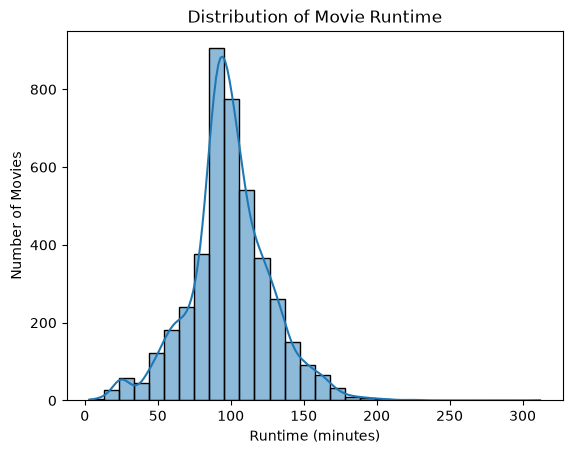

In [281]:
sns.histplot(data=df,x='minutes',kde=True,bins=30)
plt.title('Distribution of Movie Runtime')
plt.xlabel('Runtime (minutes)')
plt.ylabel('Number of Movies')
plt.show()


### Q19. Longest TV shows
Which 10 TV Shows have the most seasons? Show them as a horizontal bar chart.

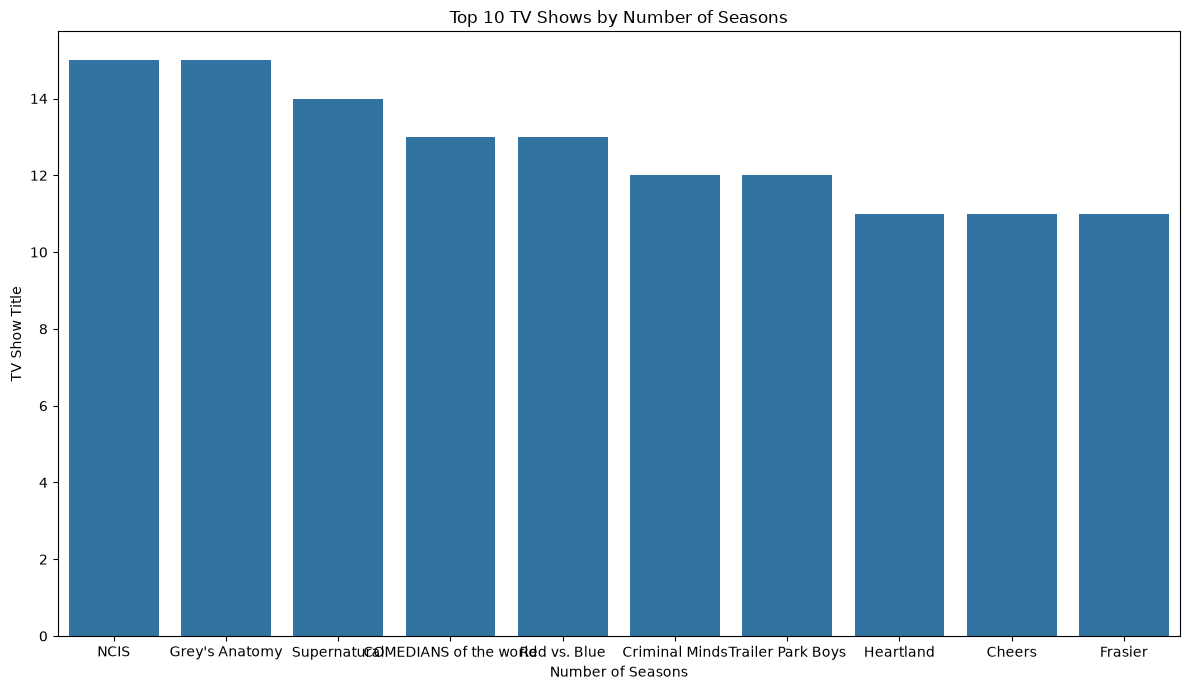

In [302]:
a=df.loc[(df['type']=='TV Show'),['title','seasons']].sort_values(by='seasons',ascending=False).head(10)
a['title']
plt.figure(figsize=(12, 7))
sns.barplot(data=a,x=a['title'],y=a['seasons'])
plt.title('Top 10 TV Shows by Number of Seasons')
plt.xlabel('Number of Seasons')
plt.ylabel('TV Show Title')
plt.tight_layout()
plt.show()


### Q20. Audience group
Create a `content_age_group` column:
- **Kids:** TV-Y, TV-Y7, TV-Y7-FV, TV-G, G
- **Teens:** TV-PG, PG, PG-13, TV-14
- **Adults:** TV-MA, R, NC-17
- **Other:** NR, UR

Then plot the share of each group by `year_added` (2015 to 2019) as a 100% stacked bar chart.

Text(0.5, 1.0, 'Stacked Bar Chart')

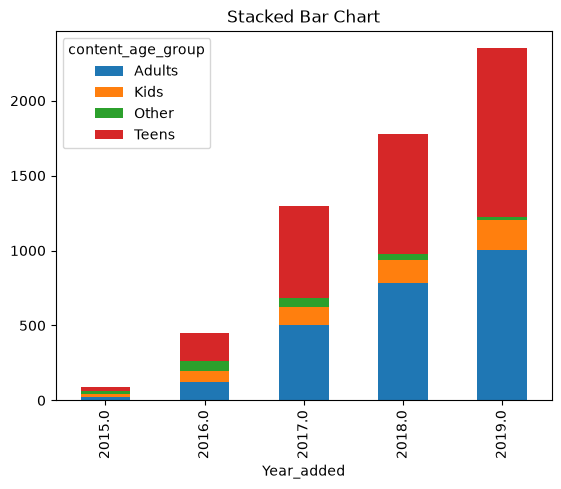

In [315]:
df['content_age_group']=df['rating'].map({'TV-Y':'Kids','TV-Y7':'Kids','TV-Y7-FV':'Kids','TV-G':'Kids','G':'Kids',
                                          'TV-PG':'Teens','PG':'Teens','PG-13':'Teens','TV-14':'Teens',
                                          'TV-MA':'Adults','R':'Adults','NC-17':'Adults',
                                          'NR':'Other','UR':'Other'})

between_years=df[df['Year_added'].between(2015,2019)]
stacked_barchart=between_years.groupby(['Year_added','content_age_group'])['content_age_group'].count().unstack()
stacked_barchart.plot(kind='bar',stacked=True)
plt.title('Stacked Bar Chart')




### Q21. Runtime buckets
Using `pd.cut`, bucket movie runtimes into **Short (<60)**, **Medium (60–120)** and **Long (>120)**. Which bucket is largest? Plot the counts.

In [326]:
df['Duration'] = pd.cut(
    df['minutes'],
    bins=[-float('inf'), 60, 120, float('inf')],
    labels=['Short', 'Medium', 'Long'],
    right=False
)
df.groupby('Duration')['Duration'].count()

## From the output given, we can conclude that the Medium bucket 

Duration
Short      330
Medium    3076
Long       859
Name: Duration, dtype: int64

### Q22. Release lag
Create `release_lag = year_added - release_year`. Report the mean and median lag, and the percentage of titles added in the **same year** they were released.

In [345]:
df['release_lag']=df['Year_added']-df['release_year']
print(f"the release mean lag is {df['release_lag'].mean()} and the release median lag is {df['release_lag'].median()}")


the release mean lag is 4.621083078900852 and the release median lag is 1.0


np.int64(2146)

In [351]:
same_year=df.loc[(df['Year_added']==df['release_year']),'title'].count()
Percentage_of_titlesadd=(100*same_year)/df['title'].count()
print("The percentage id titkes added in the same year they released is",Percentage_of_titlesadd)


The percentage id titkes added in the same year they released is 34.42412576195059


### Q23. Best month
In which month does Netflix add the most content? Plot a bar chart ordered January to December.

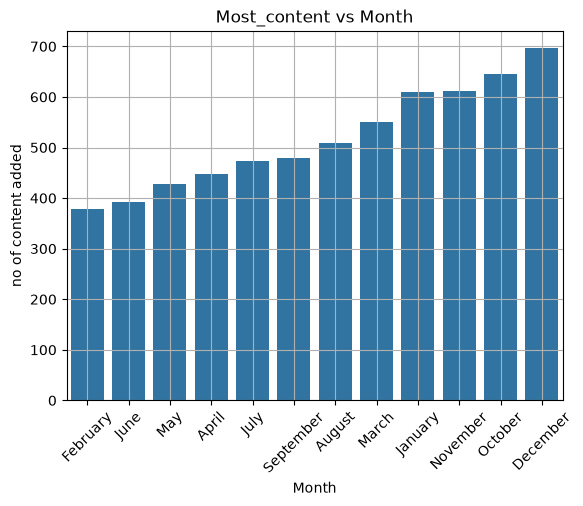

In [422]:
ordered_chart=df.groupby('Month')['title'].count().sort_values()
plt.figsize=(100,5)
plt.tight_layout()
sns.barplot(x=ordered_chart.index,y=ordered_chart.values)
plt.xticks(rotation=45)
plt.ylabel('no of content added')
plt.title("Most_content vs Month")
plt.grid()



## From the Graph ploted below, we can conclude that the month December has the Highest content added



---
# Level 4: Advanced (multi-valued columns, pivots, time series)
*Skills: explode, pivot_table, heatmap, groupby().agg(), rolling*

### Q24. Genre analysis
Find the top 15 genres overall, then compare the top 10 genres for Movies vs TV Shows side by side (two subplots).

In [421]:
#Top 15 Generes Overall 
df['listed_in'].value_counts().sort_values().tail(15)

listed_in
International TV Shows, TV Dramas                    92
Dramas, International Movies, Thrillers              93
Comedies, International Movies, Romantic Movies      97
Action & Adventure, Dramas, International Movies    103
Dramas, International Movies, Romantic Movies       108
Comedies, International Movies                      120
Children & Family Movies                            120
Children & Family Movies, Comedies                  129
Documentaries, International Movies                 150
Kids' TV                                            159
Comedies, Dramas, International Movies              174
Dramas, Independent Movies, International Movies    186
Dramas, International Movies                        248
Stand-Up Comedy                                     273
Documentaries                                       299
Name: count, dtype: int64

Text(0, 0.5, 'No of TV Shows')

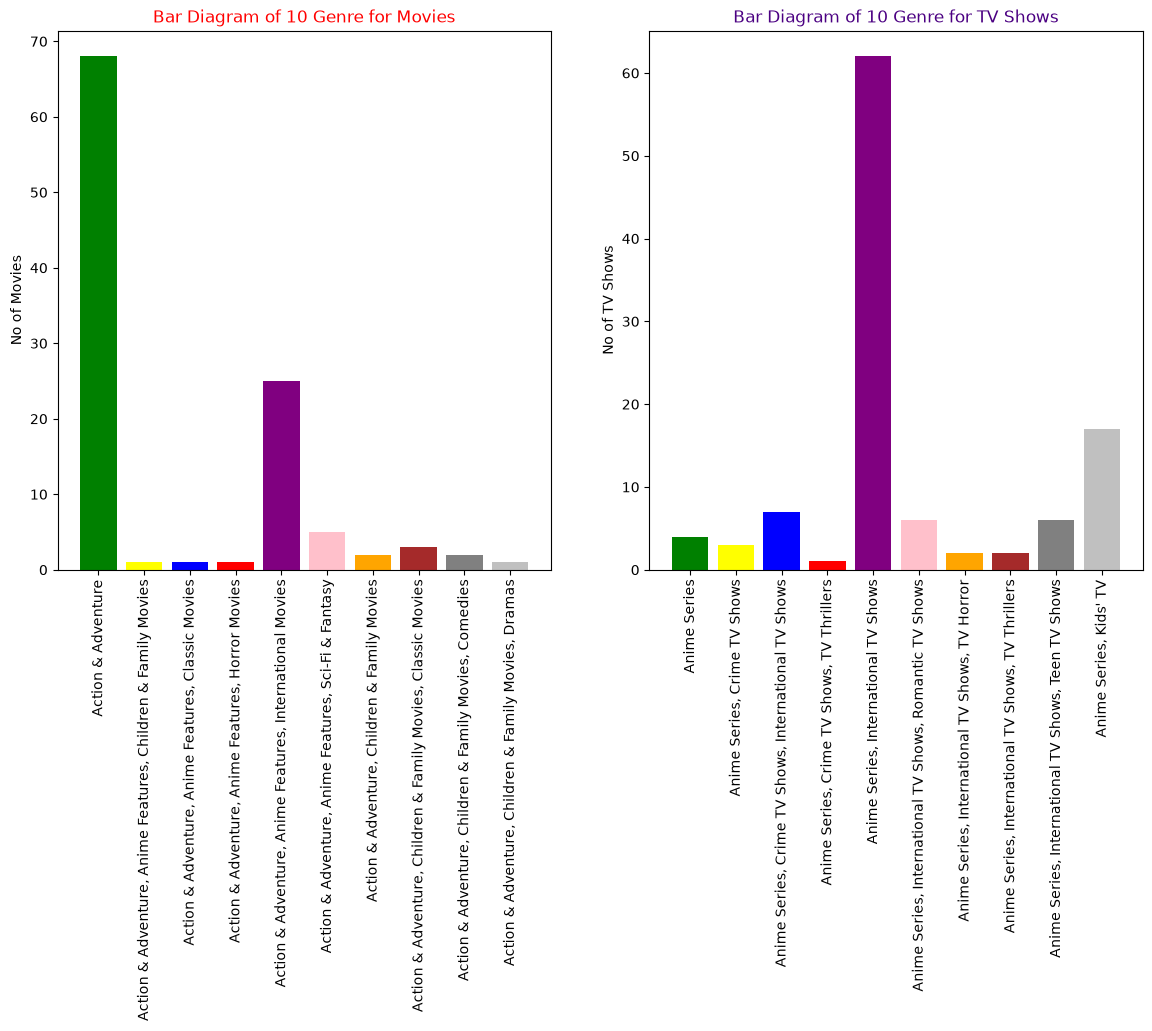

In [414]:
Movies_generes=df[df['type']=='Movie']
Movies_generes = Movies_generes.groupby('listed_in')['listed_in'].count().head(10)
fig,ax=plt.subplots(1,2,figsize=(14,7))
ax[0].tick_params(axis='x', rotation=90)
ax[0].bar(Movies_generes.index,Movies_generes.values,color=['green','Yellow','blue','red','purple','pink','orange','brown','grey','silver'])
ax[0].set_title('Bar Diagram of 10 Genre for Movies',color='red')
ax[0].set_ylabel('No of Movies')

TV_generes=df[df['type']=='TV Show']
TV_generes = TV_generes.groupby('listed_in')['listed_in'].count().head(10)
ax[1].tick_params(axis='x', rotation=90)
ax[1].bar(TV_generes.index,TV_generes.values,color=['green','Yellow','blue','red','purple','pink','orange','brown','grey','silver'])
ax[1].set_title('Bar Diagram of 10 Genre for TV Shows',color='indigo')
ax[1].set_ylabel('No of TV Shows')

### Q25. Country analysis (all countries)
Using all countries listed for each title (exclude "Unknown"), find the top 10 countries. How does this list differ from your answer in Q10?

In [427]:
Excluded=df[df['title'] !='Unknown']
Excluded.groupby('country')['title'].count().sort_values().tail(10)



##The core concepts of the both questions are likely to be same but the only difference here is that in Q10, use the bar plot to show the
# distributions and according to that, we made a conclusion. but here, we directly plot the distrbution on the table format and according 
# to that we made an conclusion


country
Turkey              79
Mexico              83
France              90
Spain              117
South Korea        136
Canada             141
Japan              176
United Kingdom     348
India              777
United States     2032
Name: title, dtype: int64

### Q26. Growth by type
Plot a line chart of titles added per `year_added` for Movies and TV Shows. Why does 2020 look so low? (Answer in a comment.)

Text(0, 0.5, 'No of Tittle')

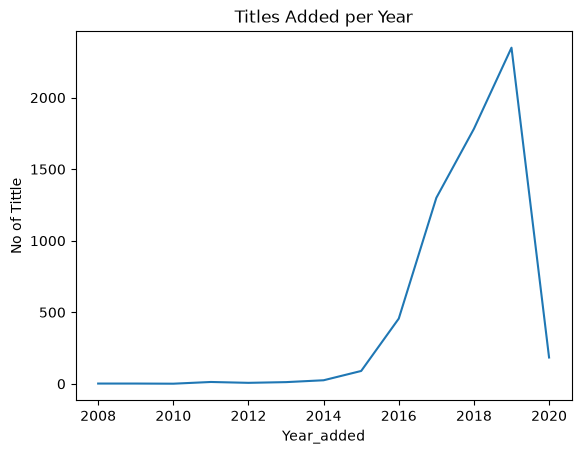

In [431]:
titles_added_perYear=df.groupby('Year_added')['title'].count()
sns.lineplot(x=titles_added_perYear.index,y=titles_added_perYear.values)
plt.title('Titles Added per Year')
plt.ylabel('No of Tittle')

## 2020 looks so low because the the no of movie release in year 2018 and 2019 is generally higher than which become slightly low 
## in year 2020 .

### Q27. Year × month heatmap
Build a `pivot_table` with `year_added` as rows and `month_added` as columns (values = count of titles) and show it as a `sns.heatmap` with annotations. Which periods show the biggest surge?

<Axes: xlabel='Month', ylabel='Year_added'>

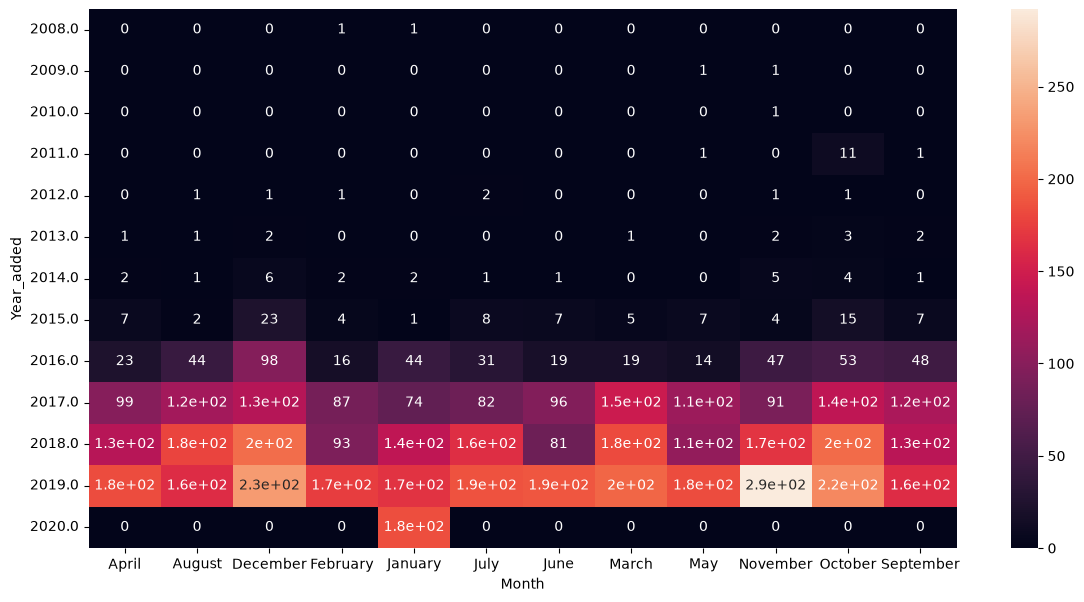

In [455]:
pivoted=df.pivot_table(index='Year_added',columns='Month', values='title',aggfunc='count',fill_value=0)
plt.figure(figsize=(14, 7))
plt.tight_layout()
plt.title('Year × month heatmap')
sns.heatmap(pivoted,annot=True)


## The biggest surge in the title is in year 2019 .


### Q28. Country × genre heatmap
For the top 10 countries and top 10 genres, build a count matrix and plot a heatmap. Which country specialises in which genre?

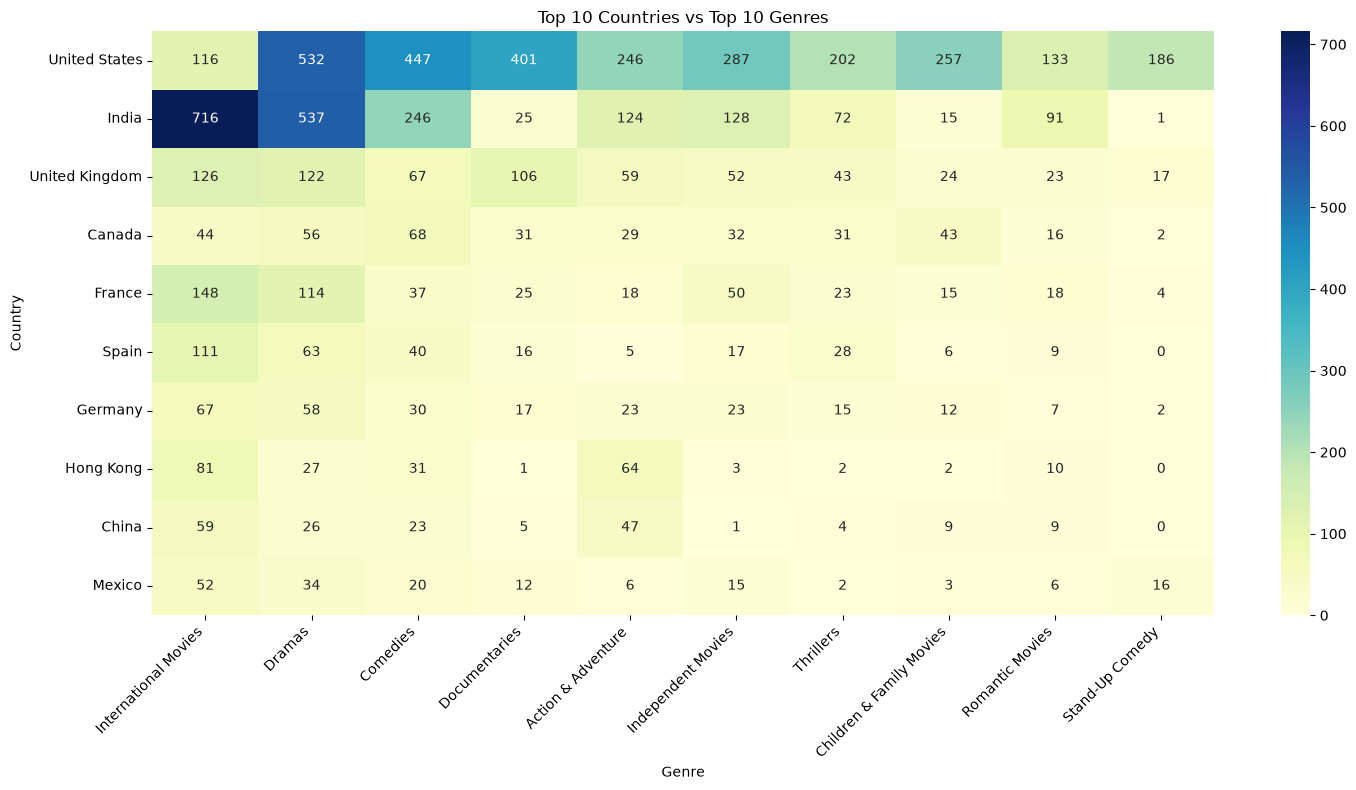

In [483]:
# Remove duplicate combinations and reset the index
pairs = pairs.drop_duplicates(
    ['title', 'country', 'genre']
).reset_index(drop=True)

# Build the count matrix
count_matrix = pd.crosstab(
    pairs['country'],
    pairs['genre']
).reindex(
    index=top_countries,
    columns=top_genres,
    fill_value=0
)

# Plot the heatmap
plt.figure(figsize=(15, 8))

sns.heatmap(
    count_matrix,
    annot=True,
    fmt='d',
    cmap='YlGnBu'
)

plt.title('Top 10 Countries vs Top 10 Genres')
plt.xlabel('Genre')
plt.ylabel('Country')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Q29. Director productivity
Excluding "Unknown", find the top 10 directors by title count. For each, show the title count, the average movie runtime and their most frequent genre.

In [500]:
df_clean

excluding_UN= df_clean[df_clean['director']!='Unknown']
title_count=excluding_UN.groupby('director')['title'].count().sort_values(ascending=False).head(10)
average_movie=excluding_UN.groupby('director')['minutes'].mean().sort_values(ascending=False).head(10)
most_frequent_genre=excluding_UN.groupby('director')['listed_in'].count().sort_values(ascending=False).head(10)
print(f"The top 10 directors by title count is {title_count}")
print()
print(f"The top 10 directors by averge movie runtine is {average_movie}")
print()
print(f"The top 10 directors by most frequent genre is {most_frequent_genre}")


The top 10 directors by title count is director
Raúl Campos, Jan Suter    18
Marcus Raboy              14
Jay Karas                 13
Jay Chapman               12
Martin Scorsese            9
Steven Spielberg           9
David Dhawan               8
Johnnie To                 8
Lance Bangs                8
Quentin Tarantino          7
Name: title, dtype: int64

The top 10 directors by averge movie runtine is director
David Lean                     200.000000
Ashutosh Gowariker             198.800000
Bassam Kurdali                 196.000000
Raj Kapoor                     191.333333
Lawrence Kasdan                191.000000
Peter Jackson                  190.000000
Sooraj R. Barjatya             187.000000
Lewis Milestone, Carol Reed    185.000000
Radhu Karmakar                 181.000000
Abdellatif Kechiche            180.000000
Name: minutes, dtype: float64

The top 10 directors by most frequent genre is director
Raúl Campos, Jan Suter    18
Marcus Raboy              14
Jay Karas    

### Q30. Most frequent actors
Excluding "Unknown", find the 15 most frequent actors. Then show the top 5 actors separately for Movies and TV Shows.

In [519]:
Excluding_Unknown = df_clean[
    (df_clean['cast'] != 'Unknown')
]

most_frequent_actors = (
    Excluding_Unknown['cast']
    .str.split(',')
    .explode()
    .str.strip()
    .value_counts()
    .head(15)
)


print(most_frequent_actors)

cast
Anupam Kher         33
Shah Rukh Khan      30
Naseeruddin Shah    27
Om Puri             27
Akshay Kumar        26
Yuki Kaji           26
Takahiro Sakurai    25
Paresh Rawal        25
Amitabh Bachchan    24
Boman Irani         23
Andrea Libman       22
Ashleigh Ball       22
John Cleese         22
Kareena Kapoor      19
Tara Strong         18
Name: count, dtype: int64


In [534]:
Excluding_Unknown= df_clean[
    (df_clean['cast'] != 'Unknown')
]
extracted_movies= Excluding_Unknown[ Excluding_Unknown['type']=='Movie']
top_5_actors_Movies=extracted_movies['cast'].str.split(',').explode().str.strip().value_counts().head(5)
print("The Top 5 Movies Actor are            ",top_5_actors_Movies)
print()
print()
extracted_TV_Shows= Excluding_Unknown[ Excluding_Unknown['type']=='TV Show']
top_5_TV_Shows_actors=extracted_TV_Shows['cast'].str.split(',').explode().str.strip().value_counts().head(5)
print("The Top 5 TV Shows actors are       ",top_5_TV_Shows_actors)

The Top 5 Movies Actor are             cast
Anupam Kher         32
Shah Rukh Khan      30
Naseeruddin Shah    27
Om Puri             27
Akshay Kumar        26
Name: count, dtype: int64


The Top 5 TV Shows actors are        cast
Takahiro Sakurai      18
Yuki Kaji             16
David Attenborough    14
Daisuke Ono           14
Ashleigh Ball         12
Name: count, dtype: int64


### Q31. Rating mix by country
For the top 8 countries, compute the percentage of titles in each `content_age_group` and display a 100% stacked horizontal bar chart. What does it suggest about local content strategy?

<Axes: xlabel='country'>

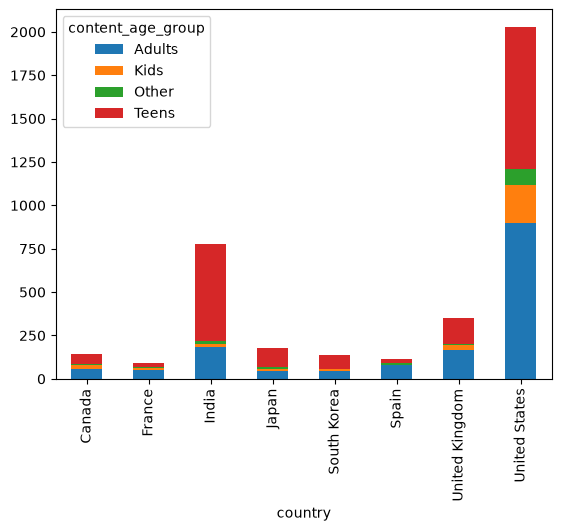

In [556]:
name_of_countries=df['country'].str.split(',').explode().str.strip().value_counts().head(8).index
top_8_countries=df[df['country'].isin(name_of_countries)]
title_counts=top_8_countries.groupby(['country','content_age_group'])['title'].count().unstack()
title_percentage = 100*title_counts/df['title'].count()
print("The percentage of ",title_percentage)

# Ploting a stacked bar chart, here we go through
title_counts.plot(kind='bar',stacked=True)

### Q32. Is Netflix shifting to TV Shows?
For each `year_added`, compute the ratio of TV Shows to total titles. Plot the trend along with a 2-year rolling average.

Text(0, 0.5, 'Ratios of TV Shows to the total titles')

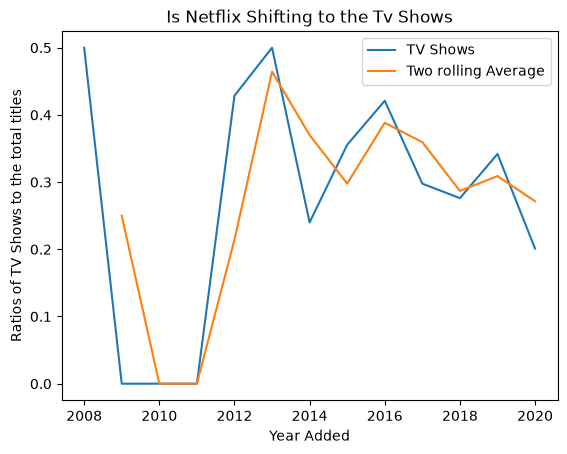

In [595]:
TV_Shows=df[df['type']=='TV Show']

total_title= df.groupby('Year_added')['title'].count()
total_TV_Shows=TV_Shows.groupby('Year_added')['type'].count()
ratios=total_TV_Shows/total_title
ratios=ratios.fillna(0)
rolling_avg=ratios.rolling(window=2).mean()
rolling_avg

plt.plot(ratios.index,ratios.values,label='TV Shows')
plt.plot(rolling_avg.index,rolling_avg.values, label='Two rolling Average')
plt.legend()
plt.title('Is Netflix Shifting to the Tv Shows')
plt.xlabel('Year Added')
plt.ylabel('Ratios of TV Shows to the total titles')

### Q33. Older catalog
How many titles were released before 2000? Show their top genres and ratings, and plot the number of titles by **decade**.

In [580]:
before_2000=df[df['release_year']<2000]
total_no_of_titles=before['title'].count()
total_no_of_titles

# The total no of titles release before 2000 is 379.

np.int64(379)

In [588]:
# Top Genres 
Top_Genres=before_2000['listed_in'].str.split(',').explode().str.strip().value_counts().head(1)
Top_rating=before_2000['rating'].str.split(',').explode().str.strip().value_counts().head(1)
print(f"The Top Genres is {Top_Genres}")
print()
print(f"The Top rating is {Top_rating}")


The Top Genres is listed_in
Dramas    145
Name: count, dtype: int64

The Top rating is rating
TV-14    76
Name: count, dtype: int64


Text(0, 0.5, 'No of titles')

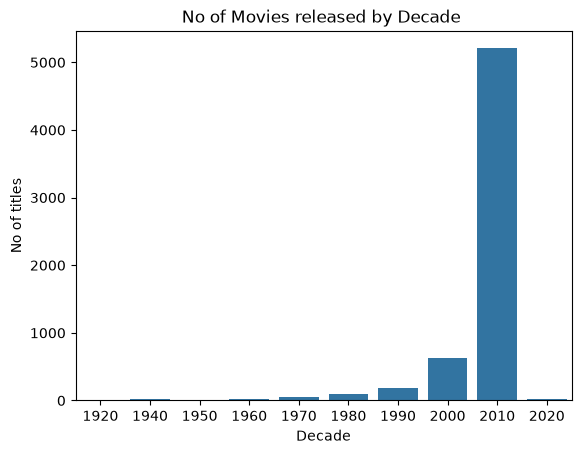

In [617]:
Decades=df.dropna(subset='release_year').copy()
Decades['release_year']=Decades['release_year'].astype(int)
Decades['Decade']=(Decades['release_year']//10)*10

no_of_titles=Decades['Decade'].value_counts().sort_index()
sns.barplot(x=no_of_titles.index,y=no_of_titles.values)
plt.title("No of Movies released by Decade ")
plt.ylabel('No of titles')

---
# Level 5: Expert (text mining, data quality, business case)
*Skills: text processing, boxplot/violin, IQR, co-occurrence, custom functions*

### Q34. Text mining
Using `description`, find the 20 most frequent words after removing stop words and words shorter than 4 letters. Do the top words differ between Movies and TV Shows? Plot both.

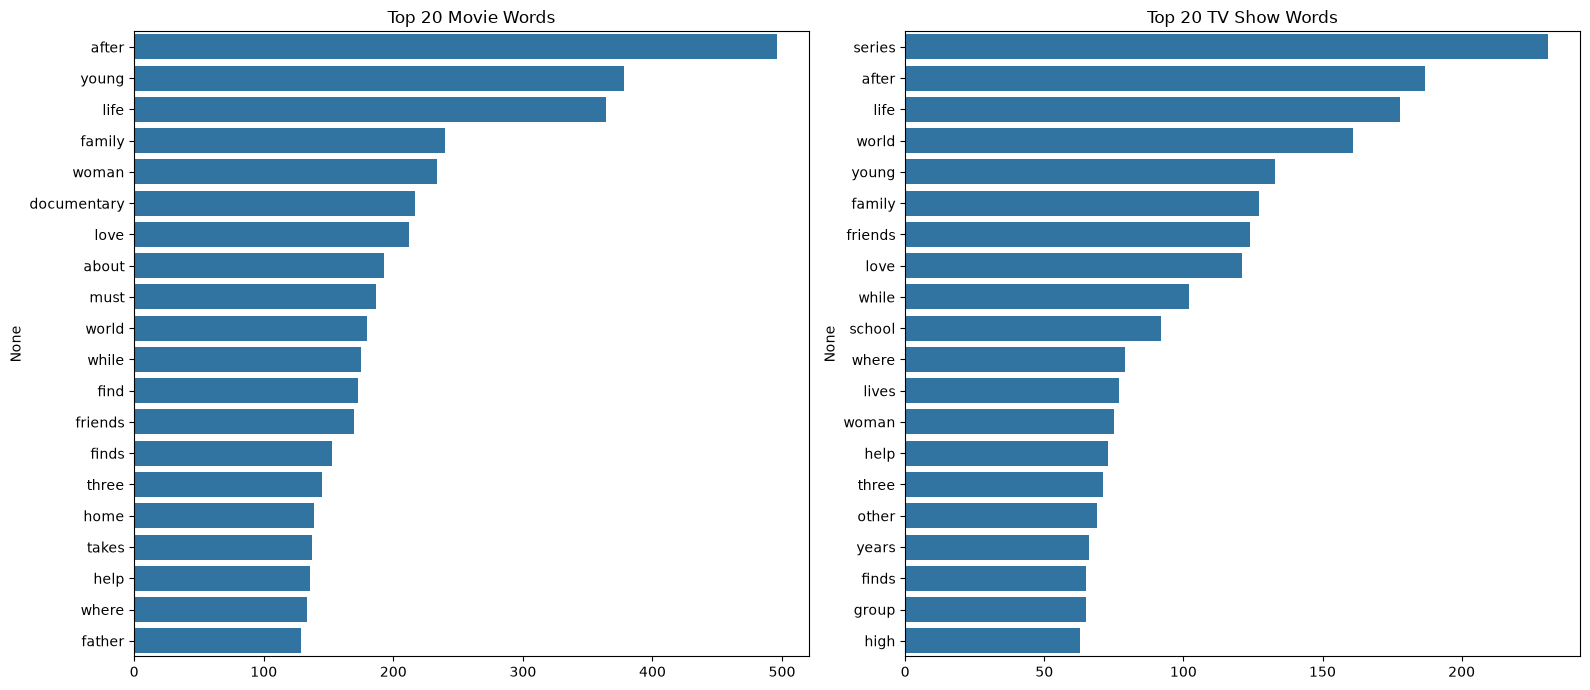

In [176]:
stop_words = ['the', 'and', 'with', 'from', 'that', 'this',
              'have', 'their', 'when', 'been', 'were', 'will',
              'your', 'they', 'them', 'into', 'only', 'what']

movie_words = []
show_words = []

for description in df[df['type'] == 'Movie']['description'].dropna():
    for word in description.lower().replace(',', '').replace('.', '').split():
        if len(word) >= 4 and word not in stop_words:
            movie_words.append(word)

for description in df[df['type'] == 'TV Show']['description'].dropna():
    for word in description.lower().replace(',', '').replace('.', '').split():
        if len(word) >= 4 and word not in stop_words:
            show_words.append(word)

movie_count = pd.Series(movie_words).value_counts().head(20)
show_count = pd.Series(show_words).value_counts().head(20)


fig, ax = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(x=movie_count.values, y=movie_count.index, ax=ax[0])
ax[0].set_title('Top 20 Movie Words')

sns.barplot(x=show_count.values, y=show_count.index, ax=ax[1])
ax[1].set_title('Top 20 TV Show Words')

plt.tight_layout()
plt.show()

### Q35. Description length vs genre
Create `desc_length` (word count of `description`). Compare it across the top 8 genres using a boxplot or violin plot.

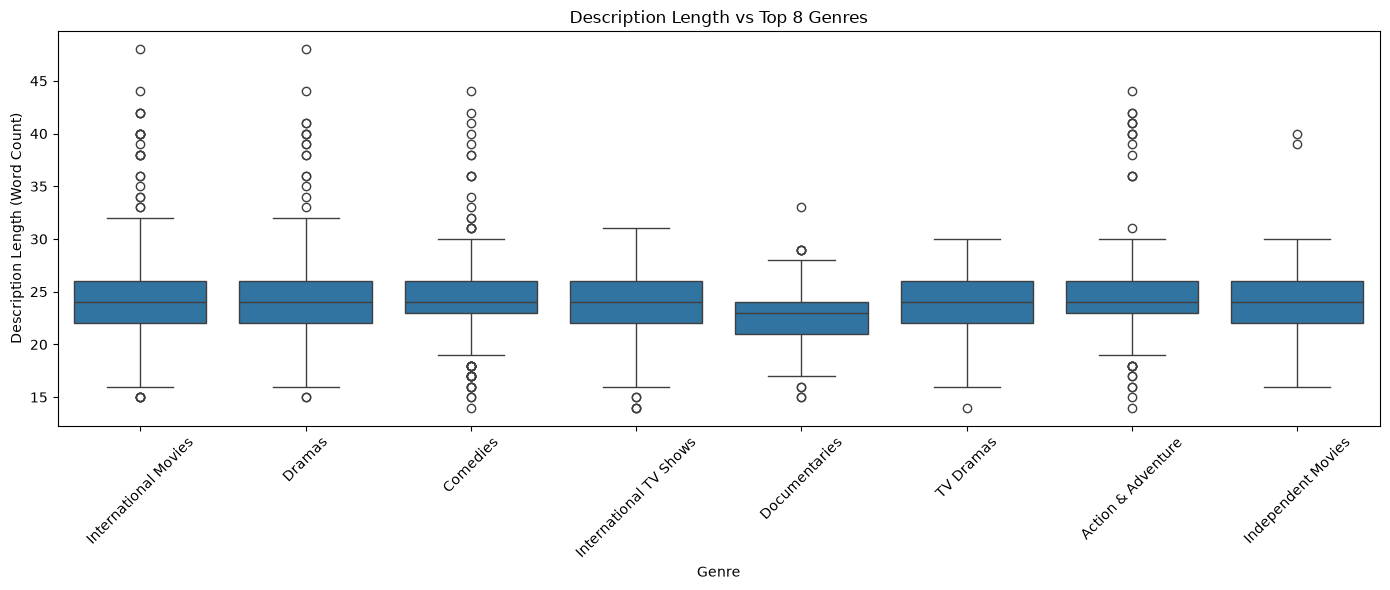

In [22]:

df['desc_length'] = df['description'].str.split().str.len()
genre_df = df[['listed_in', 'desc_length']].dropna().copy()
genre_df['listed_in']= genre_df['listed_in'].str.split(', ')
genre_df = genre_df.explode('listed_in')
top_8_genres = genre_df['listed_in'].value_counts().head(8).index
top_genre_df = genre_df[
    genre_df['listed_in'].isin(top_8_genres)]
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=top_genre_df,
    x='listed_in',
    y='desc_length',
    order=top_8_genres
)

plt.title('Description Length vs Top 8 Genres')
plt.xlabel('Genre')
plt.ylabel('Description Length (Word Count)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Q36. Data quality audit
Find rows where `year_added < release_year` (negative `release_lag`). How many are there? Show 5 examples and, in a markdown cell, explain whether you would drop, fix or flag them, and why.

In [45]:
Negative_release_lag= df[df['Year_added']<df['release_year']]
print(f" There are {sum(Negative_release_lag.count())} no of rows where year_added < release_year")

##I would flag these rows for review rather than drop or fix them immediately.
# Reason: The examples show that Year_added is later than release_year, which is normal.
#     For example, Incoming was released in 2018 and added to Netflix in 2019.
# Therefore, these rows are not negative release lags.
#     The condition Year_added < release_year identifies titles that appear to have been added to Netflix before their release year.

 There are 119 no of rows where year_added < release_year


### Q37. Outlier detection (IQR)
Using the IQR method, flag outliers in movie `minutes`. Show a boxplot, then list the 10 longest and 10 shortest movies.

In [47]:
Negative_release_lag

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,desc_length,Year_added
518,80202352,Movie,Incoming,Eric Zaragosa,"Scott Adkins, Aaron McCusker, Vahldin Prelic, ...","Serbia, United States",2018-10-26,2019,TV-MA,89 min,"Action & Adventure, Sci-Fi & Fantasy",When an imprisoned terrorist cell hijacks a hi...,22,2018.0
1315,81034946,TV Show,Maradona in Mexico,NaN,Diego Armando Maradona,"Argentina, United States, Mexico",2019-11-13,2020,TV-MA,1 Season,"Docuseries, Spanish-Language TV Shows","In this docuseries, soccer great Diego Maradon...",27,2019.0
2028,70259177,TV Show,Jack Taylor,Stuart Orme,"Iain Glen, Killian Scott, Nora-Jane Noone, Tar...","United States, Ireland",2013-03-31,2016,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Dramas",Ken Bruen's bestselling crime novels leap to l...,19,2013.0
3144,80190946,Movie,Hans Teeuwen: Real Rancour,Doesjka van Hoogdalem,Hans Teeuwen,Netherlands,2017-07-01,2018,TV-MA,86 min,Stand-Up Comedy,Comedian Hans Teeuwen rebels against political...,17,2017.0
4587,80091880,TV Show,Tokyo Trial,NaN,"Marcel Hensema, Paul Freeman, Irrfan Khan, Sta...","Canada, Japan, Netherlands",2016-12-13,2017,TV-14,1 Season,"International TV Shows, TV Dramas","In the wake of World War II, 11 Allied judges ...",25,2016.0
4662,80229852,TV Show,Little Singham,NaN,"Swapnil Kumari, Jigna Bhardwaj, Sonal Kaushal,...",NaN,2018-12-01,2019,TV-Y7,1 Season,"Kids' TV, TV Comedies","A spinoff of Rohit Shetty's action franchise, ...",24,2018.0
5784,80025384,TV Show,Unbreakable Kimmy Schmidt,NaN,"Ellie Kemper, Jane Krakowski, Tituss Burgess, ...",United States,2018-05-30,2019,TV-14,4 Seasons,TV Comedies,When a woman is rescued from a doomsday cult a...,26,2018.0
5789,70140358,TV Show,Arrested Development,NaN,"Jason Bateman, Portia de Rossi, Will Arnett, M...",United States,2018-05-29,2019,TV-14,5 Seasons,TV Comedies,It's the Emmy-winning story of a wealthy famil...,25,2018.0
6087,80025744,TV Show,Sense8,NaN,"Tuppence Middleton, Brian J. Smith, Doona Bae,...",United States,2016-12-23,2018,TV-MA,2 Seasons,"TV Dramas, TV Mysteries, TV Sci-Fi & Fantasy","From the creators of ""The Matrix"" and ""Babylon...",23,2016.0


### Q38. Genre co-occurrence matrix
Build a matrix showing how often two genres appear on the same title (for the top 12 genres) and plot it as a heatmap. Which pairs are most common?

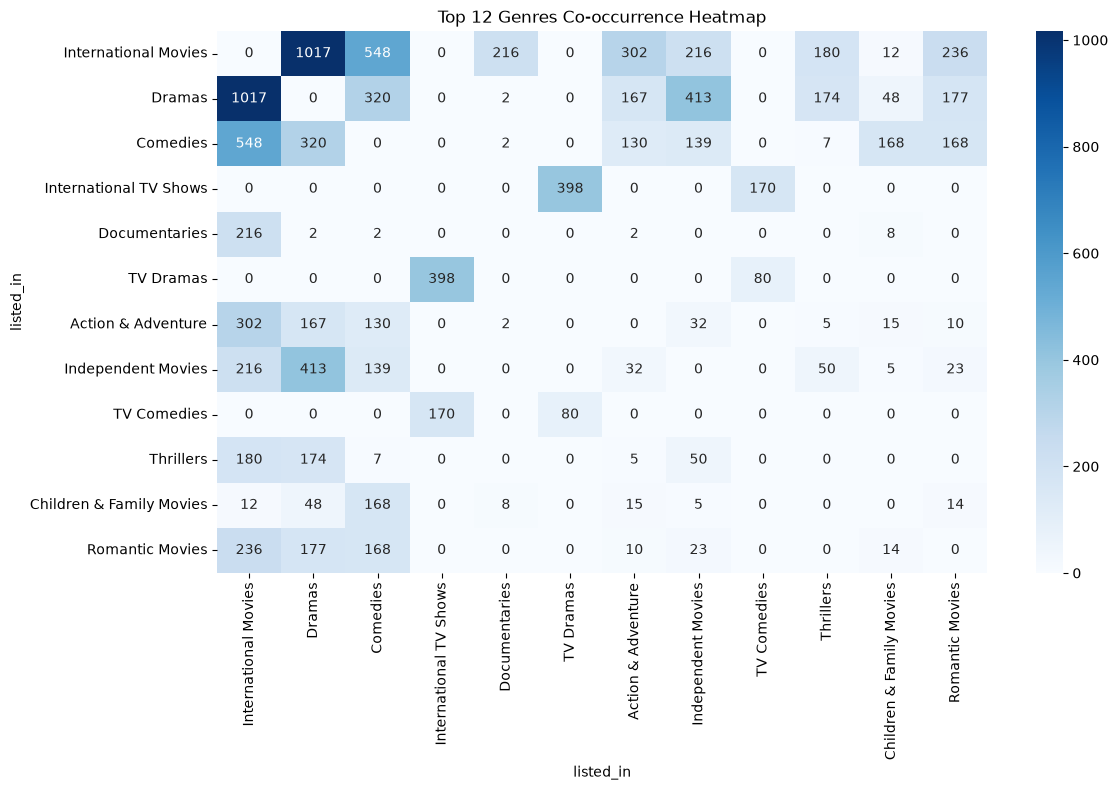

[(('Dramas', 'International Movies'), 1017), (('Comedies', 'International Movies'), 548), (('Dramas', 'Independent Movies'), 413), (('International TV Shows', 'TV Dramas'), 398), (('Comedies', 'Dramas'), 320)]


In [54]:
genres = df['listed_in'].dropna().str.split(', ').explode()
top12 = genres.value_counts().head(12).index

matrix = pd.DataFrame(0, index=top12, columns=top12)

pairs = {}

for row in df['listed_in'].dropna().str.split(', '):
    row = list(set(row) & set(top12))

    for g1 in row:
        for g2 in row:
            if g1 < g2:
                pair = (g1, g2)
                pairs[pair] = pairs.get(pair, 0) + 1

for (g1, g2), count in pairs.items():
    matrix.loc[g1, g2] = count
    matrix.loc[g2, g1] = count
plt.figure(figsize=(12, 8))
sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues')
plt.title('Top 12 Genres Co-occurrence Heatmap')
plt.tight_layout()
plt.show()

sorted_pairs = sorted(
    pairs.items(), key=lambda x: x[1], reverse=True
)

print(sorted_pairs[:5])

### Q39. Market gap analysis
For the top 10 countries, compute each country's share of titles per top-10 genre. Compare to the global share and find the genres where a country is most **under**-represented. Show the difference as a heatmap with a diverging colormap.

In [663]:
#Each Country's share of title per top-10 genres.

top_10_countries=df['country'].str.split(',').explode().str.strip().value_counts().sort_values(ascending=False).head(10).index
top_10_Genres=df['listed_in'].str.split(',').explode().str.strip().value_counts().sort_values(ascending=False).head(10).index
filter_data=df[df['country'].isin(top_10_countries) & df['listed_in'].isin(top_10_Genres)]
share_of_title=filter_data.groupby(['country','listed_in'])['title'].count().reset_index(name='title_count')
pivoted_table_1= share_of_title.pivot_table(index='listed_in',columns='country',values='title_count',fill_value=0)
pivoted_table_1

country,Canada,India,Spain,United Kingdom,United States
listed_in,,,,,
Action & Adventure,3.0,0.0,0.0,5.0,37.0
Comedies,1.0,0.0,0.0,9.0,52.0
Documentaries,7.0,0.0,0.0,37.0,203.0
Dramas,2.0,1.0,0.0,3.0,60.0
Independent Movies,0.0,0.0,0.0,0.0,1.0
International Movies,0.0,0.0,0.0,1.0,0.0
International TV Shows,0.0,1.0,0.0,0.0,0.0
TV Comedies,3.0,0.0,0.0,0.0,43.0
TV Dramas,2.0,0.0,0.0,0.0,20.0


In [686]:
df1 = df.copy()
df1['country'] = df1['country'].str.split(', ')
df1['listed_in'] = df1['listed_in'].str.split(', ')
df1 = df1.dropna(subset=['country', 'listed_in'])
df1 = df1.explode('country')
df1 = df1.explode('listed_in')
result = df1.groupby(['country', 'listed_in']).size()
result = result.reset_index(name='title_count')
pivoted_table_2=result.pivot_table(index='listed_in',columns='country',values='title_count',fill_value=0)
pivoted_table_2

country,Afghanistan,Albania,Argentina,Armenia,Australia,Austria,Azerbaijan,Bangladesh,Belgium,Bermuda,...,United Kingdom,"United Kingdom,",United States,"United States,",Uruguay,Vatican City,Venezuela,Vietnam,West Germany,Zimbabwe
listed_in,,,,,,,,,,,,,,,,,,,,,
Action & Adventure,0.0,0.0,3.0,0.0,10.0,0.0,0.0,0.0,9.0,0.0,...,59.0,0.0,247.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0
Anime Features,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Anime Series,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,9.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
British TV Shows,0.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0,...,192.0,0.0,22.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Children & Family Movies,0.0,0.0,2.0,0.0,16.0,0.0,0.0,0.0,4.0,0.0,...,24.0,0.0,258.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
Classic & Cult TV,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,6.0,0.0,16.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Classic Movies,0.0,0.0,1.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0,...,11.0,0.0,61.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
Comedies,0.0,0.0,10.0,0.0,14.0,0.0,0.0,1.0,13.0,0.0,...,67.0,0.0,447.0,0.0,1.0,0.0,0.0,2.0,1.0,0.0
Crime TV Shows,0.0,0.0,4.0,0.0,8.0,0.0,0.0,0.0,6.0,0.0,...,43.0,0.0,115.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


<Axes: xlabel='country', ylabel='listed_in'>

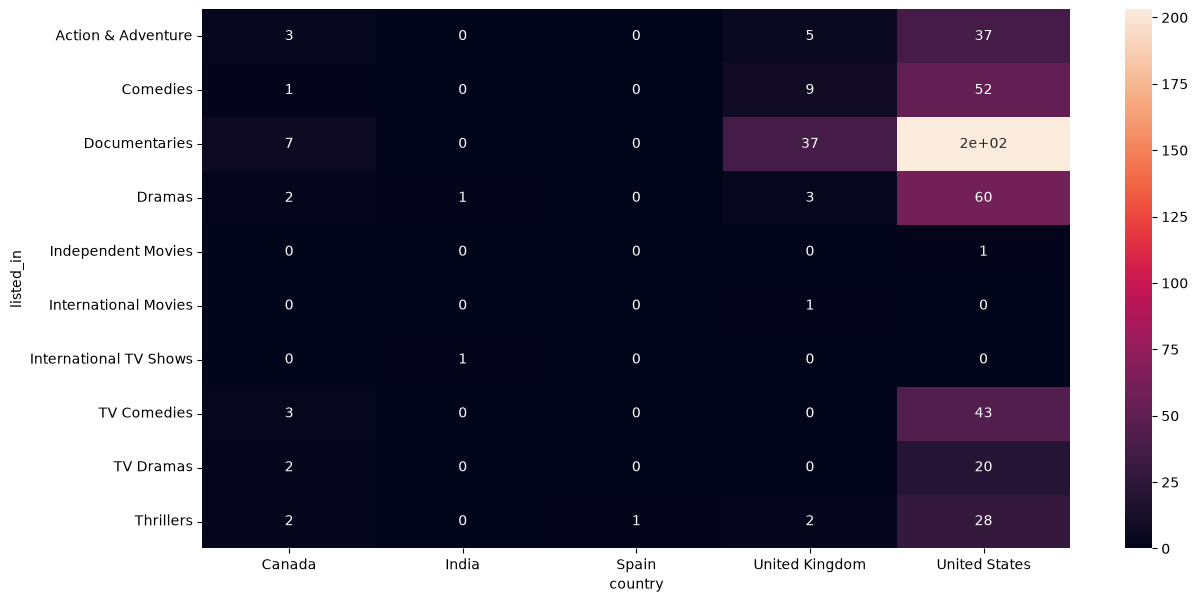

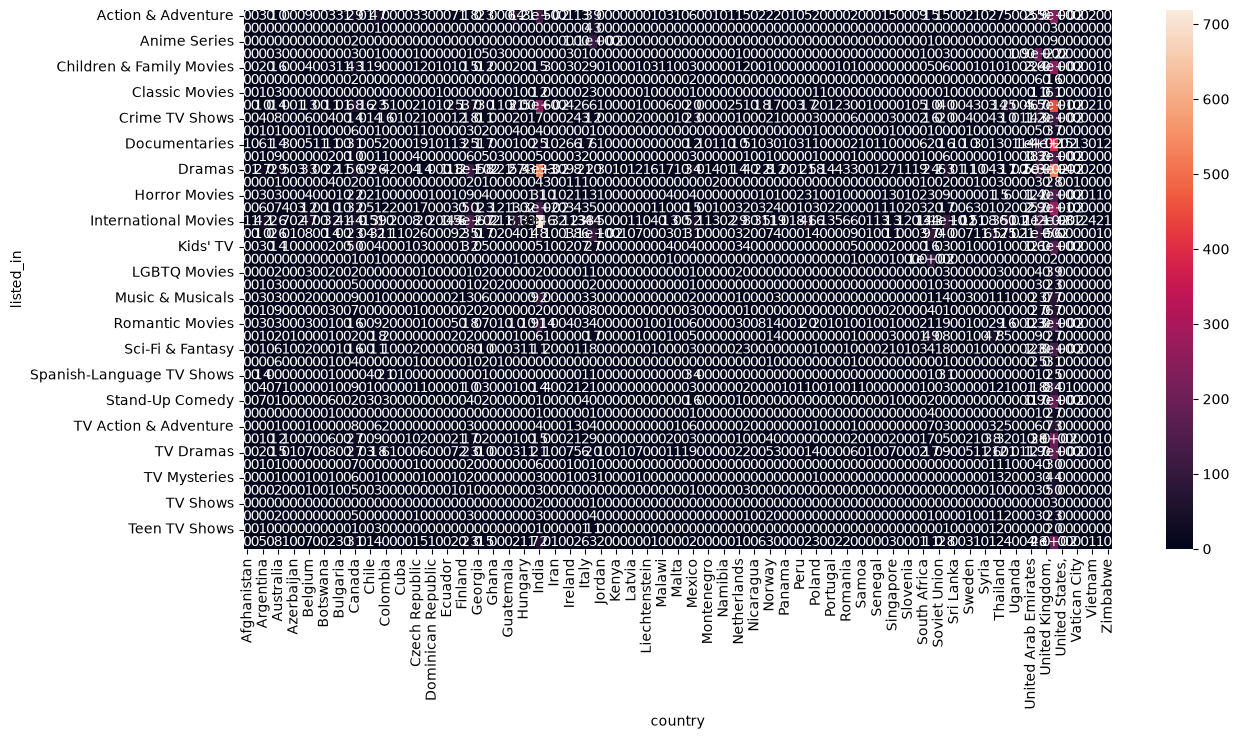

In [698]:
# How lobal Comparsio varies Top 10 Country

fig,ax=plt.subplots(1,1,figsize=(14,7))
sns.heatmap(pivoted_table_1,annot=True)

fig,ax=plt.subplots(1,1,figsize=(14,7))
sns.heatmap(pivoted_table_2,annot=True)

### Q40. Build a reusable function
Write `catalog_summary(country)` that returns a dictionary with:
- total titles
- Movie / TV Show split
- top 3 genres
- top 3 directors (exclude "Unknown")
- average movie runtime
- most common rating

Test it on `"India"`, `"Japan"` and `"Nepal"`. What happens when a country has very few titles or no movies? Handle that case gracefully.

In [21]:
def catalog_summary(country):
    d = df[df['country'].str.contains(country, na=False, case=False)]
    if d.empty:
        return {'total_titles': 0}
    movies = d[d['type'] == 'Movie']
    return {
        'total_titles': len(d),
        'movie_tv_split': d['type'].value_counts().to_dict(),
        'top_3_genres': d['listed_in'].str.split(', ').explode().value_counts().head(3).to_dict(),
        'top_3_directors': d['director'].dropna().str.split(', ').explode().loc[lambda x: x.str.lower() != 'unknown'].value_counts().head(3).to_dict(),
        'average_movie_runtime': pd.to_numeric(movies['duration'].str.extract(r'(\d+)')[0], errors='coerce').mean(),
        'most_common_rating': d['rating'].mode().iloc[0] if d['rating'].notna().any() else None
    }

for c in ['India', 'Japan', 'Nepal']:
    print(catalog_summary(c))

{'total_titles': 838, 'movie_tv_split': {'Movie': 783, 'TV Show': 55}, 'top_3_genres': {'International Movies': 719, 'Dramas': 539, 'Comedies': 246}, 'top_3_directors': {'Umesh Mehra': 8, 'David Dhawan': 8, 'S.S. Rajamouli': 7}, 'average_movie_runtime': np.float64(126.41890166028097), 'most_common_rating': 'TV-14'}
{'total_titles': 231, 'movie_tv_split': {'TV Show': 156, 'Movie': 75}, 'top_3_genres': {'International TV Shows': 112, 'Anime Series': 107, 'International Movies': 44}, 'top_3_directors': {'Toshiya Shinohara': 4, 'Masahiko Murata': 4, 'Hiroyuki Seshita': 4}, 'average_movie_runtime': np.float64(94.73333333333333), 'most_common_rating': 'TV-14'}
{'total_titles': 2, 'movie_tv_split': {'Movie': 2}, 'top_3_genres': {'Comedies': 2, 'International Movies': 2, 'Action & Adventure': 1}, 'top_3_directors': {'Stanley Tong': 1, 'Paakhi Tyrewala': 1}, 'average_movie_runtime': np.float64(94.5), 'most_common_rating': 'TV-PG'}


---
# Capstone Mini-Project: Content Strategy Dashboard

> *You are a data analyst at a streaming company. Management wants to know where the content catalog is heading and where to invest next.*

Create **one figure** with a 2×3 grid of subplots (`fig, axes = plt.subplots(2, 3, figsize=(20, 10))`):

1. Growth of titles by type over the years
2. Top genres by type
3. Country contribution (top 10)
4. Audience / rating mix
5. Runtime distribution (movies) or season distribution (TV)
6. One insight chart of your own choice

Then write **3 to 5 business recommendations** in a markdown cell, each backed by a number from your analysis.

Text(0.5, 1.0, 'is Genere have a higher proportion of Movies compared to TV Shows')

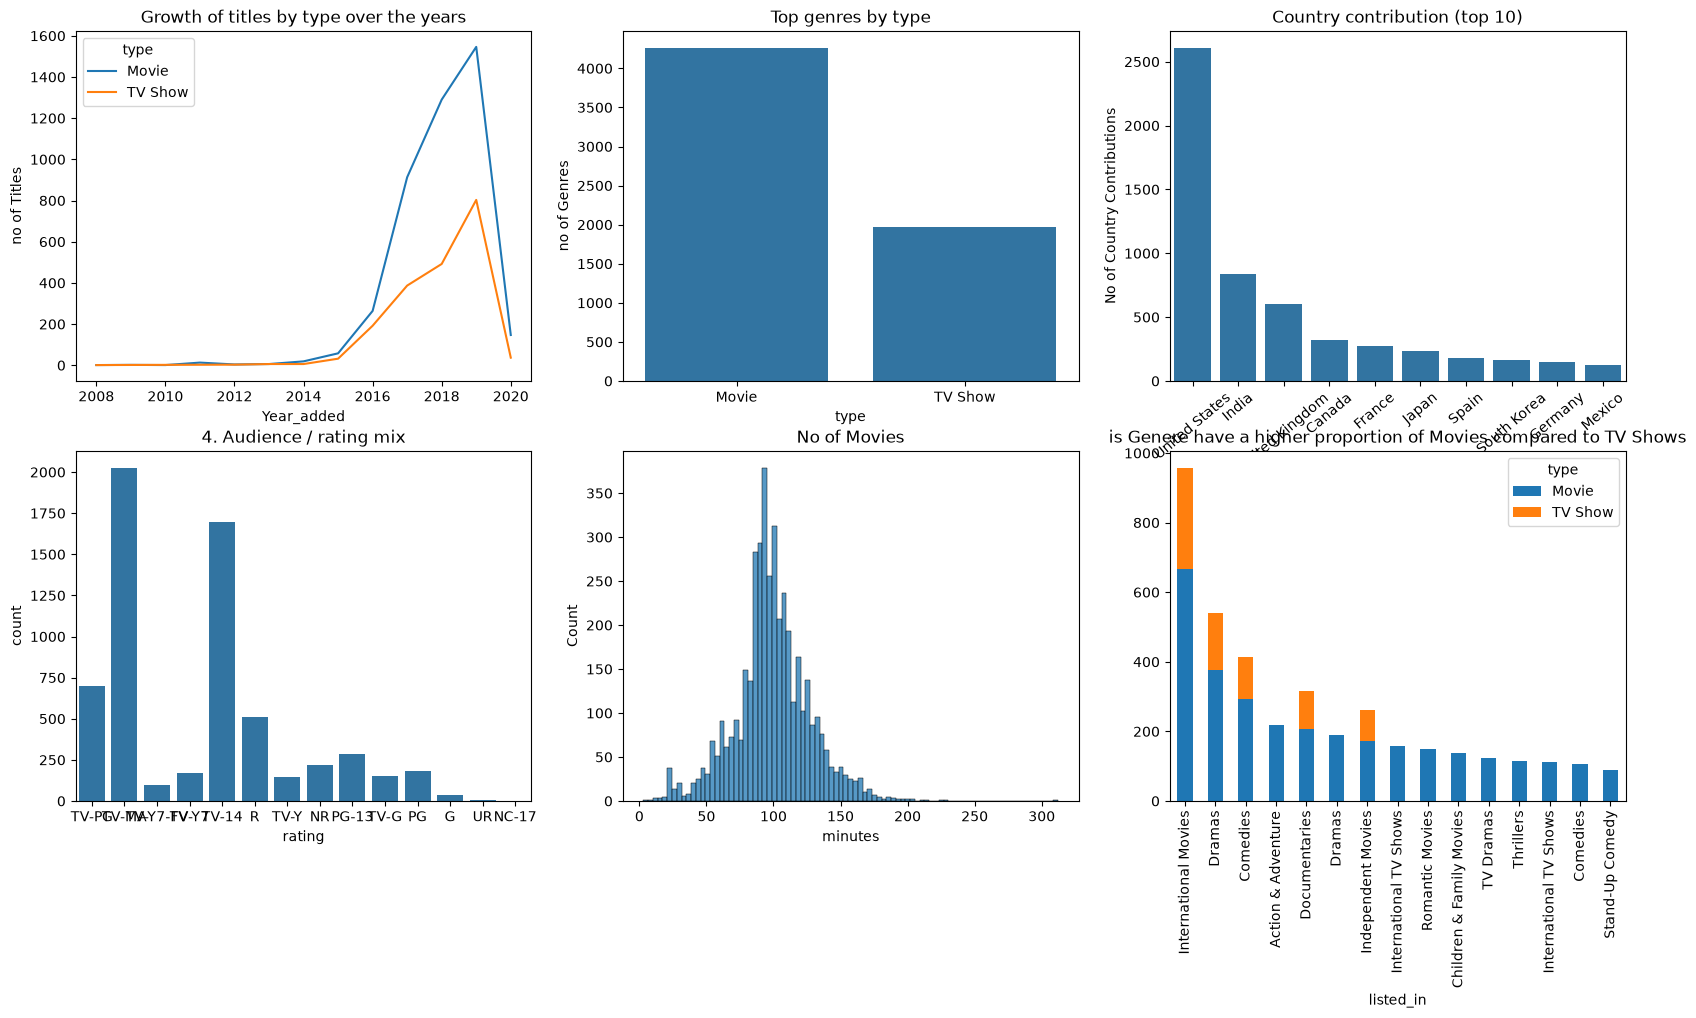

In [175]:
#1.Growth of titles by type over the years
fig, ax= plt.subplots(2,3,figsize=(20,10))
TTY=df.groupby(['Year_added','type'])['title'].count().reset_index(name='no of Titles')
sns.lineplot(data=TTY,x='Year_added',y='no of Titles',hue='type',ax=ax[0,0])
ax[0,0].set_title('Growth of titles by type over the years')

#2.Top genres by type
df_1=df.copy()
df_1=df_1.assign(listed_in=df['listed_in'].str.split(',').explode('listed_in'))
top_generes_by_type=df_1.groupby('type')['listed_in'].count().sort_values(ascending=False)
sns.barplot(x=top_generes_by_type.index,y=top_generes_by_type.values,ax=ax[0,1])
ax[0,1].set_title('Top genres by type')
ax[0,1].set_ylabel('no of Genres')

#3. Country contribution (top 10)
Top_10_country=df['country'].str.split(',').explode().str.strip().value_counts().sort_values(ascending=False).head(10)
sns.barplot(x=Top_10_country.index,y=Top_10_country.values,ax=ax[0,2])
ax[0,2].set_title('Country contribution (top 10)')
ax[0,2].set_ylabel('No of Country Contributions')
ax[0,2].tick_params(axis='x', rotation=40, labelsize=10)


#4. Audience / rating mix
sns.countplot(data=df,x='rating',ax=ax[1,0])
ax[1,0].set_title('4. Audience / rating mix')
ax[1,0].set_ylabel('count')

#5.Runtime distribution (movies) 
runtime_distribution=df[df['type']=='Movie']
sns.histplot(data=runtime_distribution,x='minutes',ax=ax[1,1])
ax[1,1].set_title('Movie Runtime Distributions')
ax[1,1].set_title('No of Movies')

# IT is on or statement so you can also use the belowe Season Distribution

# # Season Distribution(TV)
# Season_distribution=df[df['type']=='TV Show']
# sns.histplot(data=Season_distribution,x='seasons')



#6. One insight Chart of Your choice 
# Which genres have a higher proportion of Movies compared to TV Shows on Netflix?
df_new=df.copy()
df_new=df_new.assign(listed_in=df['listed_in'].dropna().str.split(',').explode('listed_in'))
Genres_Details = df_new.groupby(
    ['listed_in', 'type']
).size().sort_values(ascending=False).head(20).unstack(fill_value=0)
Genres_Details.plot(kind='bar',stacked=True,ax=ax[1,2])
ax[1,2].set_title('is Genere have a higher proportion of Movies compared to TV Shows')





